<a href="https://colab.research.google.com/github/LucasVinicius-sudo/Ajustes-IC/blob/main/C%C3%B3pia_de_dl_ap2_2025_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Prova — Desenvolvimento de Software com TensorFlow
**Curso/Instituição:** UFAL EDGE  
**Formato:** Jupyter Notebook  

**Instruções gerais**
- Utilize **Python 3.10+** e **TensorFlow 2.x**.
- É permitido usar `numpy`, `matplotlib`, `scikit-learn` e APIs nativas do `tf.keras`.
- Bases de dados devem ser **simples** e de fácil acesso (conforme indicado em cada questão).
- **Não** use soluções pré-treinadas/pesadas (ex.: modelos SOTA); foque em arquiteturas compactas.
- Documente as decisões de projeto (arquitetura, hiperparâmetros, callbacks) no final de cada questão.
- Mantenha os *seeds* para reprodutibilidade quando aplicável.

> Dica de ambiente: `pip install tensorflow scikit-learn matplotlib`

---


In [ ]:

# @title Imports e utilitários (executar uma vez)
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers , models
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

def plot_history(history, metric="accuracy"):
    import matplotlib.pyplot as plt
    plt.figure()
    plt.plot(history.history.get(metric, []), label=f"treino {metric}")
    valm = f"val_{metric}"
    if valm in history.history:
        plt.plot(history.history[valm], label=f"val {metric}")
    plt.xlabel("época"); plt.ylabel(metric); plt.grid(True); plt.legend(); plt.show()



## Questão 1 — Regularização em MLP

**Objetivo:** Investigar o impacto de regularização em rede MLP para **classificação binária**.

**Base de dados:** `sklearn.datasets.make_classification` (dados sintéticos).

**Tarefas**
1. Gere dados com: `n_samples=3000`, `n_features=20`, `class_sep=1.0`, `flip_y=0.03`.
2. Faça *split* `train/val/test` (70/15/15) e **padronize** com `StandardScaler`.
3. Treine um MLP sem regularização (ex.: 128→64→1) por ~30 épocas e reporte *overfitting* (curvas).
4. Treine o mesmo MLP com regularização.
5. Compare validação/teste e discuta o efeito da regularização em 5–8 linhas.

> Entregáveis: código, curvas (acc/loss), métricas de validação/teste e breve discussão.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


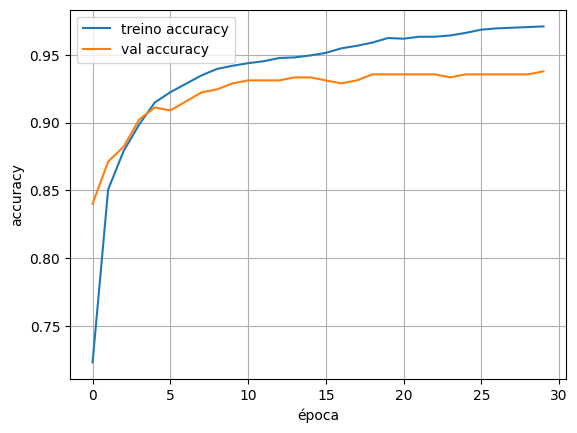

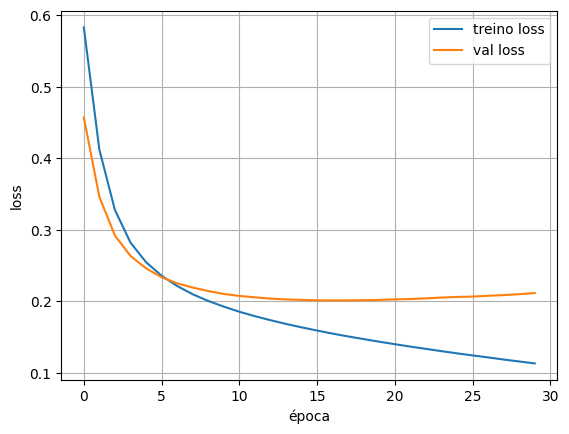

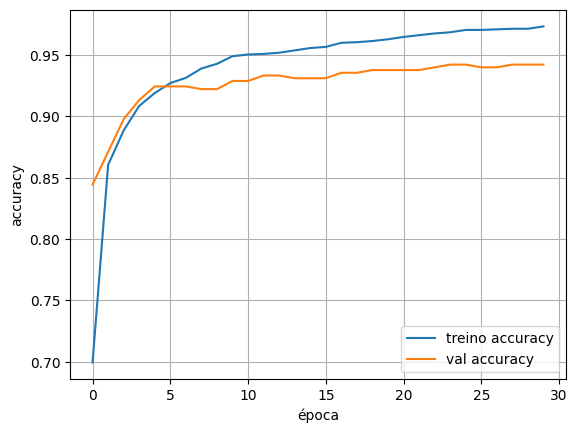

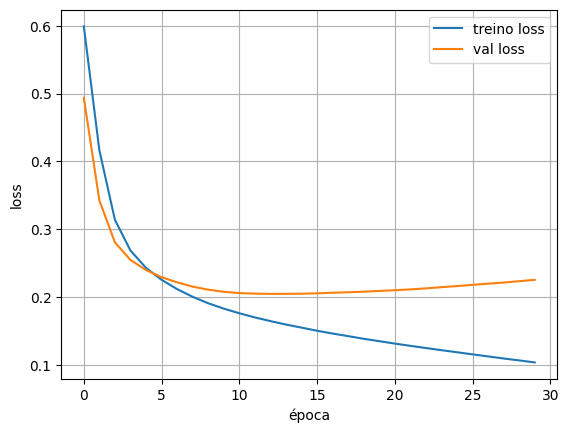

Val (sem regularizacao): [0.2117343544960022, 0.9377777576446533]
Val (com regularizacao): [0.225652277469635, 0.9422222375869751]
Teste (sem regularizacao): [0.20632125437259674, 0.9311110973358154]
Teste (com regularizacao): [0.19290147721767426, 0.9333333373069763]


In [ ]:

# ===== Sua solução Q1 =====
from sklearn.datasets import make_classification

# 1) Dados
X, y = make_classification(n_samples=3000, n_features=20, n_informative=10,
                           n_redundant=5, n_classes=2, class_sep=1.0,
                           flip_y=0.03, random_state=42)

# 2) Split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test,   y_val, y_test   = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

def build_mlp(use_regularization=False, reg_factor=0.001):
    kernel_reg = None
    if use_regularization:

        kernel_reg = regularizers.l2(reg_factor)
    model = models.Sequential()
    model.add(layers.Dense(64, activation='relu',
                           kernel_regularizer=kernel_reg,
                           input_shape=(X_train.shape[1],)))


    model.add(layers.Dense(32, activation='relu',
                           kernel_regularizer=kernel_reg))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

# 3) Sem regularização
mlp_base = build_mlp()
hist_base = mlp_base.fit(X_train, y_train, validation_data=(X_val, y_val),
                         epochs=30, batch_size=64, verbose=0)
plot_history(hist_base, "accuracy")
plot_history(hist_base, "loss")

# 4) Com regularização
mlp_regularizacao = build_mlp()
hist_regularizacao = mlp_regularizacao.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=30, batch_size=64, verbose=0)
plot_history(hist_regularizacao, "accuracy")
plot_history(hist_regularizacao, "loss")

# 5) Avaliação
print("Val (sem regularizacao):", mlp_base.evaluate(X_val, y_val, verbose=0))
print("Val (com regularizacao):", mlp_regularizacao.evaluate(X_val, y_val, verbose=0))
print("Teste (sem regularizacao):", mlp_base.evaluate(X_test, y_test, verbose=0))
print("Teste (com regularizacao):", mlp_regularizacao.evaluate(X_test, y_test, verbose=0))

# Discussão (responda em markdown abaixo)


#Discursão Markdown sobre o efeito da regularização e a comparação validação teste
*Vamos analisar a acurácia no modelo com regularização tivemos uma acurácia maior tanto no conjunto de validação tanto no conjunto de teste , no conjunto de validação tivemos 94.22 x 93.77 , já no conjunto de teste 93.33 x 93.11 , isso denuncia que a regularização ajudou a generalizar melhor o modelo , a partir desses resultados , o que é o papel fundamental da regularização evitar o sobreajuste(overfittin) , em relação a perda podemos ver que o modelo regularizado alcançou um perda de teste menor que o não regularizado o que denuncia também que as previsões nos dados não possuem apenas mais acurácia mas também , mais confiança(questão do erro de entropia de cruzada menor),


## Questão 2 — **CNN** para Classificação de Imagens

**Objetivo:** Treinar uma CNN simples para classificar **Fashion-MNIST**.

**Base:** `tf.keras.datasets.fashion_mnist` (28×28, 10 classes).

**Tarefas**
1. Carregue e normalize as imagens para `[0,1]`; separe *train/val/test*.
2. Construa uma CNN.
3. Treine por ~8–12 épocas com `Adam` e `sparse_categorical_crossentropy`.
4. Reporte acurácia em validação e teste; gere **matriz de confusão** e `classification_report`.
5. Comente brevemente (3–5 linhas) possíveis ajustes para melhorar desempenho.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


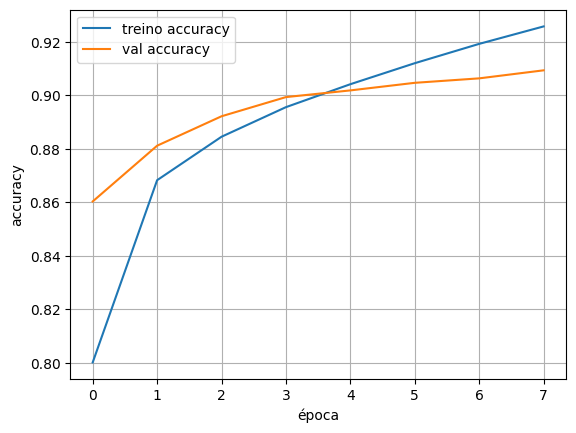

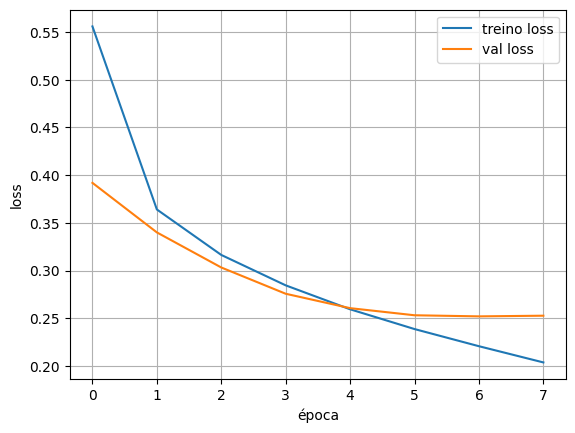

              precision    recall  f1-score   support

           0       0.83      0.87      0.85      1000
           1       1.00      0.97      0.98      1000
           2       0.85      0.84      0.85      1000
           3       0.84      0.95      0.89      1000
           4       0.90      0.78      0.84      1000
           5       0.98      0.97      0.98      1000
           6       0.74      0.71      0.73      1000
           7       0.96      0.96      0.96      1000
           8       0.96      0.98      0.97      1000
           9       0.96      0.97      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



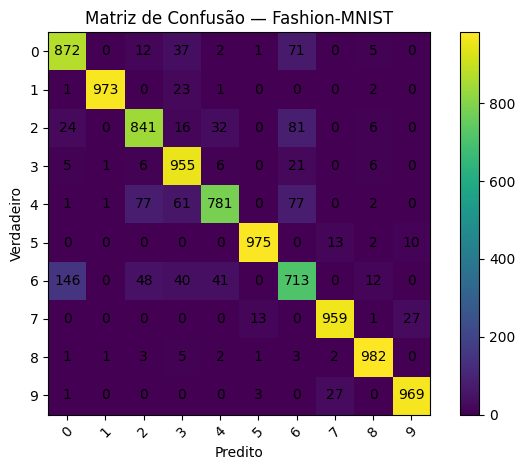

In [6]:

# ===== Sua solução Q3 =====
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train = x_train.astype("float32")/255.0
x_test  = x_test.astype("float32")/255.0

x_train = np.expand_dims(x_train, -1)
x_test  = np.expand_dims(x_test, -1)

x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.10, random_state=42, stratify=y_train)

num_classes = 10
input_shape = (28 , 28 , 1)
cnn = models.Sequential([
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu", input_shape=input_shape),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

hist = cnn.fit(x_train, y_train, validation_data=(x_val, y_val),
               epochs=8, batch_size=128, verbose=0)
plot_history(hist, "accuracy"); plot_history(hist, "loss")

# Avaliação + matriz de confusão
y_pred = np.argmax(cnn.predict(x_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)

import itertools
import matplotlib.pyplot as plt
plt.figure()
plt.imshow(cm, interpolation="nearest")
plt.title("Matriz de Confusão — Fashion-MNIST")
plt.colorbar()
ticks = np.arange(num_classes)
plt.xticks(ticks, ticks, rotation=45)
plt.yticks(ticks, ticks)
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, format(cm[i, j], 'd'), ha="center", va="center")
plt.ylabel("Verdadeiro"); plt.xlabel("Predito"); plt.tight_layout(); plt.show()


#Discurssão Markdown Questão 2
*Acredito que pode se adicionar dropout entre as camadas flatten e densa , além disso poderiamos aumentar a complexidade da rede usando mais filtros ou adicionando batchNormalization após as camadas de convolução para melhorar o apreendizado , poderiamos utilizar também data augmentation forçando o modelo a apreender features mais robustas e melhorando a generalização.

**Comentários Q3 (3–5 linhas):** _Sugira ajustes (ex.: data augmentation, batch norm, aumento de filtros)._


## Questão 3 — **RNN** (SimpleRNN/GRU/LSTM) para Séries Temporais

**Objetivo:** Classificar sequências 1D **sintéticas** em duas classes: **senoidal** vs **onda quadrada** (com ruído).

**Base:** gerada em código (sem downloads).

**Tarefas**
1. Gere `n_samples=4000`, comprimento `T=100`, frequência `f∈[0.1,0.5]`, ruído gaussiano `σ≈0.2–0.3`.
2. Faça *split* `train/val/test` (70/15/15).
3. Modele com `SimpleRNN(64)` **ou** `GRU(64)` e camada final `Dense(1, sigmoid)`.
4. Treine com `EarlyStopping` e reporte acurácia de teste e `classification_report`.
5. Plote 2–3 sequências de treino com seus rótulos para inspeção visual.


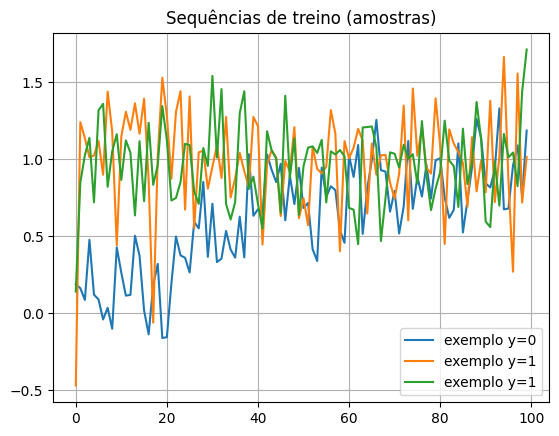

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


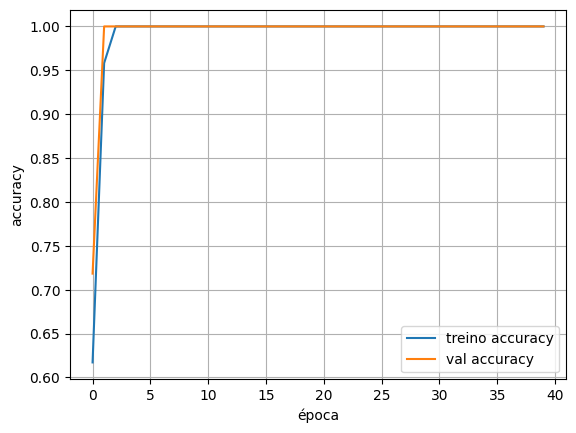

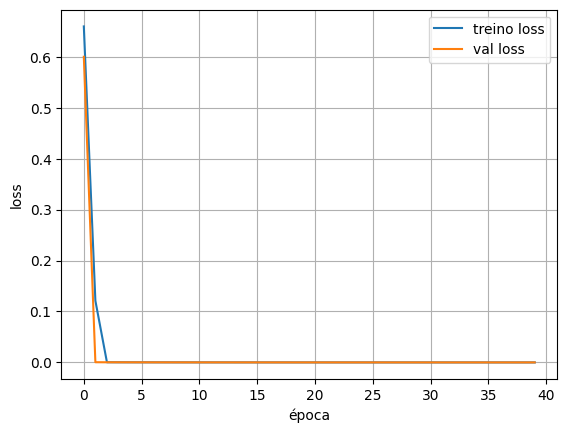

Teste: [1.4364179151016288e-05, 1.0]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       304
           1       1.00      1.00      1.00       296

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



In [7]:

# ===== Sua solução Q3 =====
def generate_sequences(n_samples=4000, T=100, f_low=0.1, f_high=0.5, noise_std=0.25):
    X = np.zeros((n_samples, T, 1), dtype=np.float32)
    y = np.zeros((n_samples,), dtype=np.int32)
    for i in range(n_samples):
        f = np.random.uniform(f_low, f_high)
        t = np.linspace(0, 1, T, endpoint=False)
        if np.random.rand() < 0.5:
            s = np.sin(2*np.pi*f*t); label = 0  # senoidal
        else:
            s = np.sign(np.sin(2*np.pi*f*t)); label = 1  # quadrada
        s += np.random.normal(0, noise_std, size=T)
        X[i,:,0] = s; y[i] = label
    return X, y

X, y = generate_sequences(4000, 100, 0.1, 0.5, 0.25)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test,   y_val, y_test   = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

# Visualização de sequências
import matplotlib.pyplot as plt
plt.figure()
for i in range(3):
    idx = np.random.randint(0, len(X_train))
    plt.plot(X_train[idx,:,0], label=f"exemplo y={y_train[idx]}")
plt.title("Sequências de treino (amostras)")
plt.legend(); plt.grid(True); plt.show()

# Modelo RNN (use GRU por padrão)
T = X_train.shape[1]
n_features = X_train.shape[2]

rnn = models.Sequential([

    layers.GRU(64, input_shape=(T, n_features)),
    layers.Dense(1, activation='sigmoid')
])




rnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy",
            metrics=["accuracy"])

es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
hist = rnn.fit(X_train, y_train, validation_data=(X_val, y_val),
               epochs=40, batch_size=64, callbacks=[es], verbose=0)

plot_history(hist, "accuracy"); plot_history(hist, "loss")
print("Teste:", rnn.evaluate(X_test, y_test, verbose=0))
y_pred = (rnn.predict(X_test, verbose=0).ravel() > 0.5).astype(int)
print(classification_report(y_test, y_pred))



---

### Observações finais
- Você pode trocar hiperparâmetros/arquiteturas mantendo a essência de cada questão.
- Caso utilize **torch/torchvision** para baixar dados, **converta** para `numpy` antes de alimentar o TensorFlow.
- Entregue o notebook com todas as **células executadas** (resultados visíveis).

> Boa prova! 🎓
